# Gaussian Mixture Modelling - Error Deconvolution

In this notebook I shall demonstrate how to use the machinery defined in this rust crate 

In [1]:
import essrs
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
N_SAMPLES: int = 500
N_BURN_IN: int = 200

In [3]:
N = 500

# Mean and covariance
mu = np.array([-2.3, 2.7])

X_SIGMA: float = 2.0
Y_SIGMA: float = 3.5
CORR: float = 0.55

Sigma = np.array([
    [X_SIGMA * X_SIGMA, X_SIGMA * Y_SIGMA * CORR],
    [X_SIGMA * Y_SIGMA * CORR, Y_SIGMA * Y_SIGMA]
])

# Cholesky decomposition: Sigma = L @ L.T
L = np.linalg.cholesky(Sigma)

# Sample N independent standard 2D Gaussians
Z = np.random.randn(N, 2)

# Transform to N(mu, Sigma)
X = mu + Z @ L.T

print(X.shape)  # (1000, 2)
print(X)

(500, 2)
[[-2.50634789e+00  6.89566394e+00]
 [-2.58668044e+00 -1.44605517e+00]
 [-1.52602245e+00  1.74684689e+00]
 [-3.78939605e+00  6.21395671e-01]
 [-4.90292860e+00  2.38942332e-01]
 [-2.39337215e+00  6.55076023e+00]
 [-7.97876977e-01  7.33412052e+00]
 [ 9.41200381e-03  3.96600659e+00]
 [ 2.67682600e-03  1.05248060e+01]
 [-5.73111220e+00 -3.00471710e+00]
 [-5.89441882e+00 -3.41298666e+00]
 [-3.10490920e+00 -1.32192755e+00]
 [-3.03267357e+00  1.67506333e-02]
 [ 8.09361018e-01  6.83897591e+00]
 [-2.93780200e-01  7.94892116e+00]
 [-1.55422021e+00  2.74039913e+00]
 [-3.48565393e+00  2.71988229e+00]
 [-1.28590455e+00  3.96421866e+00]
 [ 2.01097076e+00  5.78491690e+00]
 [-1.92744564e+00  1.79219582e+00]
 [-3.10321879e+00  8.93809867e-01]
 [-1.21485455e-01  3.48133826e+00]
 [-2.67149598e+00  2.57055071e-01]
 [-2.29513538e+00  1.28041592e+00]
 [ 1.35335214e+00  4.97583137e+00]
 [-6.90626666e+00 -5.18017042e-01]
 [-1.09582774e+00  1.26104563e+01]
 [-1.74839543e+00  9.57929078e+00]
 [-6.152670

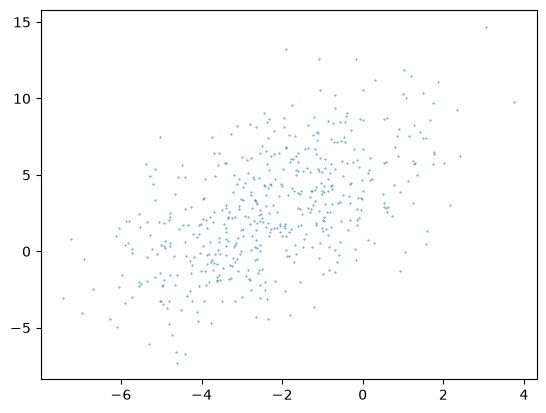

In [4]:
plt.figure()
plt.scatter(X[:, 0], X[:, 1], s=0.5, marker=".")
plt.show()

In [5]:
mu_x = np.mean(X[:, 0])
mu_y = np.mean(X[:, 1])
cov_mat = np.cov(X.T)
print(cov_mat.shape)
print(cov_mat)

x_std = np.sqrt(cov_mat[0, 0])
y_std = np.sqrt(cov_mat[1, 1])

print(x_std, y_std)

p = cov_mat[0, 1] / (x_std * y_std)
print(p)

N_PARAMETERS: int = 5
N_WALKERS: int = 50

ics = np.array([mu_x, mu_y, x_std, y_std, p]) * np.random.normal(1, 0.05, size=(N_WALKERS, N_PARAMETERS))

print(ics)

(2, 2)
[[ 3.87461123  4.14159006]
 [ 4.14159006 13.75722574]]
1.968403217890612 3.7090734342638005
0.5672671192651295
[[-2.27169817  2.50853893  1.8942475   3.84107773  0.57405425]
 [-2.22189304  2.68956285  1.99030519  3.70272581  0.5367131 ]
 [-2.28537284  2.69400186  1.72428624  3.35571369  0.54010491]
 [-2.30768586  2.6610804   1.94401074  3.81625042  0.53822434]
 [-2.22119766  2.49843907  1.88605906  3.94363229  0.568     ]
 [-2.2684262   2.70465302  2.06005029  3.5145455   0.62863194]
 [-2.37252461  2.552488    1.8825074   3.40339488  0.5407451 ]
 [-2.13635839  2.68812329  2.07687884  3.81444725  0.57476221]
 [-2.18457923  2.5507251   1.92768826  3.51735512  0.56581632]
 [-2.24723347  2.63169493  1.93083069  3.75890933  0.55371131]
 [-2.22849936  2.64109755  1.92845996  3.5633115   0.59408927]
 [-2.36319325  2.57894896  1.97768671  3.76975089  0.56151627]
 [-2.15564402  2.45486815  1.9556999   3.68923344  0.57686716]
 [-2.14765082  2.68695256  2.25912085  3.78327086  0.5669842 ]


In [6]:
start = time.perf_counter()

model = essrs.model.scientific.normal_2d_gmm_deconv(n_components=1, data=np.column_stack((X, np.zeros((X.shape[0], 3)))))

burn_move = essrs.moves.hybrid_ddc_move(one_in_n=10)
sampler_move = essrs.moves.differential_move()
config = essrs.EnsembleConfig(n_samples=N_SAMPLES, n_walkers=N_WALKERS, n_parameters=N_PARAMETERS, n_burn_in=N_BURN_IN)

fit = essrs.run_mcmc(
    log_likelihood=model,
    config=config,
    burn_in_move=burn_move,
    sampling_move=sampler_move,
    initial_conditions=ics
)

elapsed = time.perf_counter() - start
print(f"ESSRS took {elapsed:.3f} seconds")

ESSRS took 0.266 seconds


In [7]:
# fit = essrs.normal_2d.normal_2d_gmm_deconv(
#     1,
#     100,
#     100,
#     ics,
#     np.column_stack((X, np.zeros((X.shape[0], 3)))) # pad with zeros for error etc
# )

In [8]:

print("Result:")
for i, label in enumerate(["mean X", "mean Y", "sigma X", "sigma Y", "p_corr"]):
    print(f"{label} => {np.mean(fit[-1, :, i].ravel()):7.5f} +- {np.std(fit[-1, :, i].ravel()):7.5f}")


Result:
mean X => -2.25200 +- 0.08881
mean Y => 2.65615 +- 0.17309
sigma X => 1.96788 +- 0.06203
sigma Y => 3.73542 +- 0.12685
p_corr => 0.56703 +- 0.03037
